# Phân cụm

Phân cụm (clustering) chia dữ liệu thành các nhóm mà không có nhãn cho trước, ví dụ chia hồ sơ học sinh thành các nhóm có kiểu học giống nhau. Vì không có đáp án để so, kết quả phụ thuộc vào cách ta định nghĩa “gần nhau” và “một cụm”. Bài này học K-Means và DBSCAN, cách chọn số cụm, và vì sao hai thuật toán có thể chia cùng một dữ liệu theo hai cách đều hợp lý.

> **Mục tiêu**
>
> - Chạy K-Means bằng tay và tính inertia.
> - Hiểu điểm core, border, noise của DBSCAN.
> - Chọn số cụm; biết cụm tìm được không phải nhãn thật.

## K-Means

Giả định: có $K$ cụm, mỗi cụm là một “đám” tròn quanh một tâm. K-Means tìm $K$ tâm $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K$ cực tiểu tổng bình phương khoảng cách từ mỗi điểm đến tâm gần nhất (inertia):

$$J = \sum_{i=1}^{n} \min_{k}\ \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2.$$

Thuật toán Lloyd lặp hai bước đến khi không đổi:

1. **Gán**: mỗi điểm thuộc cụm có tâm gần nhất.
2. **Cập nhật**: mỗi tâm dời về trung bình các điểm của cụm.

Mỗi bước đều không làm $J$ tăng, và số cách chia là hữu hạn, nên thuật toán chắc chắn dừng. Nhưng nó chỉ dừng ở một **cực tiểu địa phương**: khởi tạo khác cho kết quả khác.

Hai cách giảm rủi ro kẹt:

- **k-means++**: chọn tâm đầu tiên ngẫu nhiên, rồi chọn mỗi tâm tiếp theo với xác suất tỉ lệ với bình phương khoảng cách từ điểm đến tâm gần nhất đã có. Nhờ vậy các tâm ban đầu thường nằm xa nhau.
- **Chạy nhiều lần** (`n_init`) và giữ kết quả có $J$ nhỏ nhất.

**Hỏi nhanh.** Có ba điểm trên trục số: 0, 1 và 10. k-means++ đã chọn tâm đầu tiên là 0. Xác suất điểm 10 được chọn làm tâm thứ hai là bao nhiêu?

- A. khoảng $0.33$
- B. khoảng $0.91$
- C. khoảng $0.99$
- D. khoảng $0.01$

<details><summary>Đáp án</summary>

C. khoảng $0.99$

Bình phương khoảng cách tới tâm gần nhất lần lượt là 0, 1 và 100, nên xác suất là $100/101$. Điểm ở xa gần như chắc chắn được chọn. Ra $10/11 \approx 0.91$ là quên bình phương.

</details>

Chi phí mỗi vòng là $O(nKd)$, nên K-Means chạy được trên dữ liệu rất lớn; `MiniBatchKMeans` còn nhanh hơn nữa.

**Chọn K.** Vẽ $J$ theo $K$ rồi tìm “khuỷu tay” (elbow method), hoặc chọn $K$ có hệ số silhouette trung bình cao nhất (mục Đánh giá cụm). Elbow chỉ là gợi ý; nên kiểm thêm cách chia có ổn định khi đổi seed, bớt mẫu không. Thường thì $K$ còn phụ thuộc mục đích: chia khách hàng thành 4 nhóm hay 6 nhóm là quyết định kinh doanh, không phải định lý.



**Giới hạn.** K-Means thích cụm tròn, kích thước gần bằng nhau, cùng mật độ. Với cụm hình trăng lưỡi liềm hay cụm lồng nhau, nó chia sai một cách rất tự tin. Tâm lại là trung bình, nên một điểm ngoại lệ đủ xa có thể kéo tâm rời khỏi đám điểm của nó: cụm gồm 1, 2, 3 và 100 có tâm ở $26.5$.

**Hỏi nhanh.** Tăng $K$ lên bằng số điểm $n$, mỗi điểm có một tâm riêng. Inertia tối ưu khi ấy bằng bao nhiêu?

- A. Bằng phương sai của dữ liệu
- B. $0$
- C. Bằng $n$
- D. Không xác định, vì cụm quá nhỏ

<details><summary>Đáp án</summary>

B. $0$

Mỗi điểm trùng với tâm của nó, nên mọi khoảng cách đều bằng 0. Vì thế không thể chọn $K$ theo inertia nhỏ nhất: tiêu chí ấy luôn kéo về phía nhiều cụm hơn.

</details>

## Ví dụ tính tay

Dữ liệu một chiều $1, 2, 9, 10, 11$, $K = 2$, khởi tạo tệ: $\mu_1 = 1$, $\mu_2 = 2$.

- Gán: $\{1\}$ về $\mu_1$; $\{2, 9, 10, 11\}$ về $\mu_2$.
- Cập nhật: $\mu_1 = 1$, $\mu_2 = 32/4 = 8$.
- Gán lại: điểm 2 giờ gần $\mu_1$ hơn ($1 < 6$), nên cụm thành $\{1, 2\}$ và $\{9, 10, 11\}$.
- Cập nhật: $\mu_1 = 1.5$, $\mu_2 = 10$. Gán lại không đổi, dừng với $J = 0.5 + 2 = 2.5$.

Lần này khởi tạo tệ vẫn tự sửa được, và $J$ giảm qua từng bước: $194 \to 50 \to 15 \to 2.5$. Nhưng chỉ cần dời một điểm là sự may mắn ấy biến mất (câu hỏi bên dưới).

Trong hai chiều cũng vậy: ba điểm $A(0, 2)$, $B(0, 1)$, $C(1, 0)$ với tâm đầu đặt ở $A$ và $B$ dừng ở $\{A\}$, $\{B, C\}$ với $J = 1$, trong khi $\{A, B\}$, $\{C\}$ chỉ có $J = 0.5$.



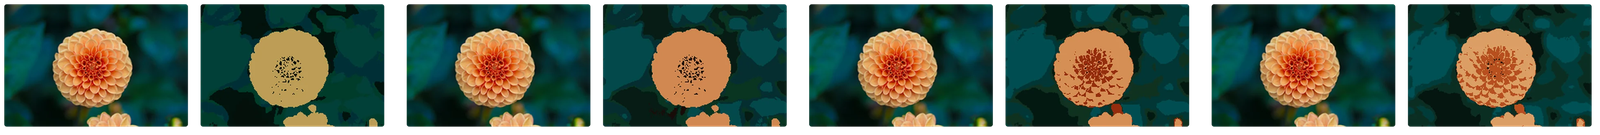

**Hỏi nhanh.** Giữ khởi tạo $\mu_1 = 1$, $\mu_2 = 2$, nhưng đổi điểm 2 thành 5, tức dữ liệu là 1, 5, 9, 10, 11. Thuật toán Lloyd dừng ở cách chia nào?

- A. $\{1, 5\}$ và $\{9, 10, 11\}$
- B. $\{1\}$ và $\{5, 9, 10, 11\}$
- C. $\{1, 5, 9\}$ và $\{10, 11\}$
- D. Không dừng, các tâm dao động mãi

<details><summary>Đáp án</summary>

B. $\{1\}$ và $\{5, 9, 10, 11\}$

Sau vòng đầu, $\mu_2 = 35/4 = 8.75$. Điểm 5 cách $\mu_2$ là 3.75, gần hơn so với $\mu_1$ (cách 4), nên không đổi cụm, và thuật toán dừng với $J = 20.75$. Cách chia $\{1, 5\}$ và $\{9, 10, 11\}$ có $J = 10$, tốt hơn hẳn. Lloyd đã kẹt ở một cực tiểu địa phương, và `n_init` có mặt chính là vì vậy.

</details>

## Cài một vòng Lloyd

Lấy bốn điểm một chiều 0, 1, 5, 6, hai tâm ban đầu 0 và 6. Mỗi điểm vào tâm gần nhất, nên nhóm trái gồm 0, 1 và nhóm phải gồm 5, 6. Tâm mới là 0.5 và 5.5. Inertia trước cập nhật là 2, sau cập nhật là 1. Code dưới cài đúng hai thao tác gán và cập nhật, và in ra các số vừa tính tay.



In [ ]:
import numpy as np

values = np.array([[0.], [1.], [5.], [6.]])
centers = np.array([[0.], [6.]])
distance2 = np.sum((values[:, None, :] - centers[None, :, :]) ** 2, axis=2)
assigned = np.argmin(distance2, axis=1)
before = np.sum(distance2[np.arange(len(values)), assigned])
new_centers = np.array([values[assigned == k].mean(axis=0) for k in range(2)])
after = np.sum((values - new_centers[assigned]) ** 2)
print("gán:", assigned.tolist())
print("tâm mới:", new_centers.ravel().tolist())
print("inertia:", float(before), "->", float(after))

gán: [0, 0, 1, 1]
tâm mới: [0.5, 5.5]
inertia: 2.0 -> 1.0


Nếu một cụm không còn điểm nào, mean của mảng rỗng là NaN, và NaN lặng lẽ lan sang mọi bước sau. Ví dụ nhỏ trên không gặp, nhưng bản cài tổng quát phải chọn trước một quy tắc cho trường hợp này.

**Hỏi nhanh.** Tự cài Lloyd bằng NumPy, tới một vòng thì có một cụm không được gán điểm nào. Xử lý thế nào là hợp lý?

- A. Coi tâm NaN là 0 rồi chạy tiếp
- B. Đặt lại tâm theo một quy tắc được ghi rõ
- C. Lấy bớt vài điểm của cụm khác chia sang
- D. Chia tổng tọa độ cho $K$ thay vì cho số điểm

<details><summary>Đáp án</summary>

B. Đặt lại tâm theo một quy tắc được ghi rõ

Trung bình của một tập rỗng không cho ra tâm nào cả. Có thể giữ tâm cũ, hoặc chuyển tâm tới điểm đang nằm xa tâm của nó nhất, như scikit-learn làm. Cách nào cũng được, miễn ghi rõ và kiểm lại xem thuật toán có hội tụ không.

</details>

## DBSCAN

Giả định: cụm là vùng **dày đặc**, ngăn cách bởi vùng thưa. Hai tham số: bán kính `eps` và số điểm tối thiểu `min_samples`.

- Điểm lõi (core): có ít nhất `min_samples` điểm trong bán kính `eps`.
- Điểm biên (border): không phải lõi nhưng nằm trong bán kính của một điểm lõi.
- Điểm nhiễu (noise): không thuộc hai loại trên, gán nhãn $-1$.

Các điểm lõi nối với nhau thành cụm. DBSCAN không cần biết trước số cụm, tìm được cụm hình dạng bất kỳ và tự loại nhiễu. Điểm yếu: một `eps` duy nhất không hợp với dữ liệu có các cụm mật độ khác nhau. HDBSCAN khắc phục điều này và thường là lựa chọn tốt hơn khi có sẵn.

**Hỏi nhanh.** Dữ liệu có hai cụm. Cụm A dày, các láng giềng thường cách nhau $0.1$. Cụm B thưa, các láng giềng thường cách nhau $0.8$. Với `eps=0.2`, DBSCAN dễ cho ra kết quả nào?

- A. Cả hai cụm đều được tìm đúng
- B. B thành cụm, còn phần lớn A thành noise
- C. A thành cụm, còn phần lớn B thành noise
- D. A và B bị gộp thành một cụm

<details><summary>Đáp án</summary>

C. A thành cụm, còn phần lớn B thành noise

Với bán kính 0.2, điểm của B hiếm khi có đủ hàng xóm. Tăng `eps` lên cỡ 0.8 thì B thành cụm, nhưng A có thể bị nối sang B nếu khe giữa hai cụm hẹp hơn mức ấy. Một giá trị `eps` không phục vụ được cả hai mật độ. HDBSCAN giải quyết việc này bằng cách quét qua nhiều mức mật độ.

</details>

## DBSCAN trên năm điểm

Trong scikit-learn, số điểm trong bán kính `eps` được đếm **tính cả chính nó**. Từ một điểm core, cụm lan qua các core lân cận rồi nhận thêm border ở rìa. Vì vậy điểm border ít hàng xóm vẫn thuộc cụm; bản cài chỉ giữ các điểm đủ ngưỡng sẽ biến mọi border thành noise, và đó đã là một thuật toán khác.



In [ ]:
from sklearn.cluster import DBSCAN

density_points = np.array([[0.], [0.1], [0.2], [0.35], [3.]])
db = DBSCAN(eps=0.16, min_samples=3).fit(density_points)
print("nhãn cụm:", db.labels_.tolist())
print("core:", db.core_sample_indices_.tolist())
assert db.labels_[-1] == -1

nhãn cụm: [0, 0, 0, 0, -1]
core: [1, 2]


Điểm 0.1 có ba điểm trong `eps`, còn 0 chỉ có hai; 0 vẫn vào cụm vì nó nối được với core 0.1. Điểm 3 quá xa nên nhãn −1. Số hiệu cụm 0, 1, … chỉ là tên tạm, có thể đổi thứ tự khi dữ liệu đổi. Một điểm border chạm được hai cụm thì thuộc cụm nào tùy thứ tự duyệt.

**Hỏi nhanh.** Giữ `eps=0.16` như ví dụ trên, nhưng đặt `min_samples=1`. Điểm 3 nhận nhãn gì?

- A. $-1$, vì vẫn ở xa mọi điểm khác
- B. Cụm 0, cùng với bốn điểm còn lại
- C. Báo lỗi, vì `min_samples` quá nhỏ
- D. Một cụm riêng, chỉ có mình nó

<details><summary>Đáp án</summary>

D. Một cụm riêng, chỉ có mình nó

Với ngưỡng 1, điểm nào cũng tự đếm chính nó, nên điểm nào cũng là core. Điểm 3 thành cụm 1 một mình, và lúc này DBSCAN không còn điểm noise nào. Theo kinh nghiệm, người ta hay đặt `min_samples` cỡ $2d$, với $d$ là số chiều.

</details>

>>>

## Hierarchical clustering

Agglomerative clustering bắt đầu với mỗi điểm là một cụm, rồi liên tục gộp hai cụm gần nhau nhất. Khoảng cách giữa hai cụm (linkage) có thể là:

- *single*: hai điểm gần nhất, tạo cụm dạng chuỗi dài;
- *complete*: hai điểm xa nhất, tạo cụm gọn;
- *average*: trung bình mọi cặp;
- *Ward*: mức tăng tổng phương sai khi gộp, gần với tinh thần của K-Means.

Kết quả là một cây gộp (dendrogram); cắt cây ở độ cao nào thì được số cụm tương ứng. Cách này cho cái nhìn nhiều tầng, nhưng tốn $O(n^2)$ bộ nhớ nên chỉ hợp với vài chục nghìn điểm.



**Hỏi nhanh.** Hai cụm trên trục số là $\{0, 1\}$ và $\{3, 10\}$. Khoảng cách giữa chúng theo single linkage và theo complete linkage lần lượt là bao nhiêu?

- A. $3$ và $9$
- B. $6$ và $6$
- C. $2$ và $6$
- D. $2$ và $10$

<details><summary>Đáp án</summary>

D. $2$ và $10$

Single linkage lấy cặp gần nhất, $|1 - 3| = 2$. Complete linkage lấy cặp xa nhất, $|0 - 10| = 10$. Còn 6 là average linkage, trung bình của bốn cặp $(3 + 10 + 2 + 9)/4$. Single linkage chỉ cần một cặp gần là gộp, nên dễ nối các cụm thành một chuỗi dài.

</details>

## Spectral clustering

Spectral clustering làm ba bước:

1. Dựng đồ thị tương đồng giữa các điểm, ví dụ nối mỗi điểm với các láng giềng gần.
2. Lấy vài vector riêng của ma trận Laplacian của đồ thị làm tọa độ mới.
3. Chạy K-Means trên tọa độ đó.

Hai điểm cùng nằm trên một “dải” dữ liệu sẽ gần nhau trong tọa độ mới dù xa nhau theo đường thẳng. Cách này mạnh với cụm không lồi, nhưng tốn kém với $n$ lớn.

Laplacian là $L = D - A$, với $A$ ma trận trọng số cạnh và $D$ ma trận đường chéo chứa bậc của mỗi đỉnh. Số trị riêng bằng 0 đúng bằng số thành phần liên thông, nên các vector riêng ứng với trị riêng nhỏ nhất chỉ ra cách cắt đồ thị.

Với hai vòng đồng tâm còn một cách thủ công: thêm đặc trưng $x^2 + y^2$, bình phương khoảng cách tới tâm, rồi chạy K-Means.



**Hỏi nhanh.** Hai vòng tròn đồng tâm, mỗi vòng là một cụm. K-Means với $K = 2$ cho ARI gần bằng 0, còn spectral clustering trên đồ thị láng giềng thì tách đúng. Lý do chính là gì?

- A. Đồ thị láng giềng gần như không có cạnh nối hai vòng
- B. Spectral clustering dùng nhiều tâm hơn K-Means
- C. Vòng trong có mật độ điểm cao hơn vòng ngoài
- D. K-Means không chạy được trên dữ liệu hai chiều

<details><summary>Đáp án</summary>

A. Đồ thị láng giềng gần như không có cạnh nối hai vòng

Hai vòng có cùng tâm, nên mọi cách chia theo tâm gần nhất đều cắt ngang cả hai vòng. Trong đồ thị láng giềng, mỗi vòng gần như là một thành phần tách rời. Các vector riêng của Laplacian gần như không đổi trên từng thành phần, nên K-Means trên tọa độ mới tách được ngay. Với `make_circles(factor=0.4)`, ARI là $0.00$ so với $1.00$.

</details>

## Đánh giá cụm

Không có nhãn thì đo độ “gọn và tách biệt”. Với điểm $i$, gọi $a(i)$ là khoảng cách trung bình đến các điểm cùng cụm, $b(i)$ là khoảng cách trung bình nhỏ nhất đến một cụm khác. Hệ số silhouette

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i),\ b(i)\}} \in [-1, 1].$$

$s$ gần 1 là điểm nằm đúng cụm, gần 0 là nằm giữa hai cụm, âm là có lẽ xếp nhầm. $b(i)$ lấy cụm khác **gần nhất**, không phải xa nhất: $a = 0.4$, khoảng cách trung bình tới hai cụm khác là 0.9 và 0.6 thì $s = (0.6 - 0.4)/0.6 \approx 0.33$.

Silhouette cũng “thích” cụm tròn, nên đánh giá thấp kết quả tốt của DBSCAN trên dữ liệu hình trăng (mục Dùng thư viện). Đừng chọn số cụm chỉ vì silhouette cao.

Inertia lại càng không dùng được để chọn $K$: inertia tối ưu không tăng khi $K$ tăng, nên “chọn $K$ có inertia nhỏ nhất” luôn đẩy về rất nhiều cụm.

**Hỏi nhanh.** Một điểm có $a(i) = 1$, tức khoảng cách trung bình tới cụm của nó, và $b(i) = 4$, tức khoảng cách trung bình tới cụm khác gần nhất. Silhouette của điểm này bằng bao nhiêu?

- A. $0.25$
- B. $3$
- C. $0.75$
- D. $-0.75$

<details><summary>Đáp án</summary>

C. $0.75$

$(4 - 1)/\max(1, 4) = 0.75$, nên điểm khá gọn trong cụm của nó. Nếu đổi chỗ $a$ và $b$ thì ra $-0.75$, dấu hiệu điểm có lẽ đã bị xếp nhầm cụm.

</details>

Nếu có nhãn thật (đề thi chấm phân cụm thường có), dùng Adjusted Rand Index (ARI) hoặc Normalized Mutual Information (NMI). Nhãn chỉ dùng để chấm, không dùng khi fit. Cả hai không phụ thuộc cách đặt tên cụm: cụm “0” của mô hình có là cụm “3” của đáp án cũng không sao. Accuracy so thẳng thì khác: chỉ cần đổi tên cụm là điểm sụp.

**Hỏi nhanh.** Nhãn tham khảo là $[0, 0, 1, 1]$, mô hình trả về $[1, 1, 0, 0]$. Accuracy so thẳng và ARI lần lượt bằng bao nhiêu?

- A. $0$ và $1$
- B. $1$ và $1$
- C. $0$ và $0$
- D. $0.5$ và $0$

<details><summary>Đáp án</summary>

A. $0$ và $1$

Hai cách chia giống hệt nhau, chỉ khác tên cụm. Accuracy so từng ID nên bằng 0. ARI xét từng cặp mẫu xem có cùng cụm hay không, nên bằng 1.

</details>

## Dùng thư viện

In [ ]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=400, noise=0.06, random_state=0)
X = StandardScaler().fit_transform(X)
for name, model in [("K-Means", KMeans(n_clusters=2, n_init=10, random_state=0)),
                    ("DBSCAN ", DBSCAN(eps=0.3, min_samples=5))]:
    labels = model.fit_predict(X)
    print(name, "ARI =", round(adjusted_rand_score(y, labels), 2),
          " silhouette =", round(silhouette_score(X, labels), 2))

K-Means ARI = 0.47  silhouette = 0.5
DBSCAN  ARI = 1.0  silhouette = 0.39


DBSCAN khớp nhãn hoàn toàn theo ARI, nhưng silhouette lại chấm K-Means cao hơn: đúng điều mục Đánh giá cụm đã cảnh báo. Con số `eps=0.3` cũng chỉ có nghĩa sau `StandardScaler`: bán kính luôn đi kèm thang đo.



**Hỏi nhanh.** Trong code trên, nhân `X` đã chuẩn hóa lên 10 lần nhưng giữ `eps=0.3`. DBSCAN sẽ trả về gì?

- A. Gần như mọi điểm thành noise
- B. Như cũ, vì hình dạng các cụm không đổi
- C. Hai mặt trăng bị gộp thành một cụm
- D. Số cụm tăng lên khoảng mười lần

<details><summary>Đáp án</summary>

A. Gần như mọi điểm thành noise

Khoảng cách tăng 10 lần mà bán kính vẫn giữ nguyên, nên hầu hết các điểm không có đủ 5 hàng xóm. Chạy thử thì 98.75% số điểm nhận nhãn $-1$. Đổi đơn vị đo thì phải đổi `eps` theo.

</details>

## Khi đi thi

- **Bài chấm bằng ARI/NMI**: thử vài thuật toán và tham số theo hình dạng dữ liệu thay vì mặc định K-Means. Phân cụm trên embedding tốt (Chương 4) thường quan trọng hơn đổi thuật toán.
- **Cụm làm bước tiền xử lý**: USA-NA-AIO 2026 (vòng 2, Problem 5) cho baseline chạy K-Means $k = 4$ trên các điểm $(x, y)$ để tách bốn đường cong trộn lẫn, rồi fit từng đường. Đường cong cắt nhau thì cụm theo tâm gần nhất trộn điểm; vượt baseline bắt đầu từ chỗ đó.
- **Cụm làm đặc trưng**: mã cụm hoặc khoảng cách đến các tâm K-Means là đặc trưng bổ sung cho mô hình có giám sát.
- **Cụm làm group cho validation**: ảnh gần trùng nhau, các bản ghi của cùng một người, nên nằm trọn trong một fold. Phân cụm giúp tìm ra các nhóm đó để dùng `GroupKFold` (bài 1.3).
- **Luôn chuẩn hóa** trước các thuật toán dựa trên khoảng cách, và chỉ fit scaler trên phần dữ liệu giao thức cho phép.

## Tóm tắt

- Phân cụm không có đáp án; mỗi thuật toán là một giả định về hình dạng cụm.
- K-Means: cụm tròn quanh tâm, nhanh, cần $K$, chỉ đạt cực tiểu địa phương; k-means++ và `n_init` giảm rủi ro kẹt.
- DBSCAN: cụm là vùng dày đặc, tự tìm số cụm và nhiễu, nhạy với `eps` và thang đo.
- Phân cấp cho cây gộp nhiều tầng; spectral xử lý cụm không lồi.
- Không nhãn thì dùng silhouette (cẩn thận với cụm không tròn); có nhãn thì dùng ARI, NMI.

## Kiểm tra cuối bài

Mười câu kiểm cả cách hiểu, phép tính và quy trình. Câu sai chỉ ra phần cần đọc lại; hãy làm trước khi mở lời giải.

**Câu 1.** Ở bước cập nhật của K-Means, một cụm đang có ba điểm $(1, 1)$, $(3, 1)$ và $(2, 4)$. Tâm mới của cụm là điểm nào?

- A. $(2, 2)$
- B. $(2, 6)$
- C. $(6, 2)$
- D. $(1, 2)$

<details><summary>Đáp án</summary>

A. $(2, 2)$

Lấy trung bình theo từng tọa độ: $((1+3+2)/3,\ (1+1+4)/3) = (2, 2)$. Đây là bước cập nhật của Lloyd, làm sau bước gán điểm.
Phỏng theo: [MIT 6.036 · Final Fall 2021 · Clustering 2(a–b)](https://introml.mit.edu/_static/fall22/final/review/6_036_Final_Fall_2021.pdf#page=6)

</details>
**Câu 2.** Có bảy điểm $x_1, \dots, x_7$, $K = 2$, hai tâm khởi tạo là $x_3$ và $x_6$. Khoảng cách từ $x_1, x_2, x_4, x_5, x_7$ tới $x_3$ lần lượt là 3, 4, 4, 3, 6. Tới $x_6$ lần lượt là 2, 7, 1, 8, 1. Sau bước gán đầu tiên, hai cụm là gì?

- A. $\{x_1, x_2, x_3, x_4\}$ và $\{x_5, x_6, x_7\}$
- B. $\{x_2, x_3, x_5\}$ và $\{x_1, x_4, x_6, x_7\}$
- C. $\{x_1, x_2, x_3, x_5\}$ và $\{x_4, x_6, x_7\}$
- D. $\{x_2, x_3, x_4, x_7\}$ và $\{x_1, x_5, x_6\}$

<details><summary>Đáp án</summary>

B. $\{x_2, x_3, x_5\}$ và $\{x_1, x_4, x_6, x_7\}$

So từng cặp khoảng cách. $x_1$ (3 so với 2), $x_4$ (4 so với 1) và $x_7$ (6 so với 1) về với $x_6$. $x_2$ (4 so với 7) và $x_5$ (3 so với 8) về với $x_3$. Bước gán chỉ cần khoảng cách, không cần tọa độ.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q8.3](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=46)

</details>
**Câu 3.** Chạy k-means++ trên năm điểm $(0,0)$, $(1,2)$, $(2,3)$, $(3,1)$, $(4,1)$ với $K = 3$, tâm đầu tiên là $(0, 0)$. Xác suất $(4, 1)$ được chọn làm tâm thứ hai là bao nhiêu?

- A. khoảng $0.200$
- B. khoảng $0.314$
- C. khoảng $0.378$
- D. khoảng $0.250$

<details><summary>Đáp án</summary>

C. khoảng $0.378$

Bình phương khoảng cách tới $(0, 0)$ lần lượt là 5, 13, 10, 17, tổng là 45, nên xác suất là $17/45 \approx 0.378$. Quên bình phương thì ra khoảng $0.314$. Chọn đều thì ra $0.2$ hoặc $0.25$.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q8.2](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=44)

</details>
**Câu 4.** Hai lần khởi tạo K-Means với cùng $K$ cho inertia 12 và 9 trên cùng dữ liệu. Theo inertia thì chọn kết quả nào, và điều gì vẫn chưa kết luận được?

- A. Chọn kết quả 9, nhưng chưa chứng minh được đó là cực tiểu toàn cục
- B. Chọn kết quả 12, vì lần khởi tạo đầu ổn định hơn
- C. Kết quả 9 chắc chắn là toàn cục, vì thấp hơn 12
- D. Hai kết quả phải bằng nhau, vì mỗi bước Lloyd đều tối ưu chính xác

<details><summary>Đáp án</summary>

A. Chọn kết quả 9, nhưng chưa chứng minh được đó là cực tiểu toàn cục

Mỗi bước của Lloyd không làm mục tiêu tăng, nhưng điều đó không bảo đảm tới được nghiệm toàn cục. Chạy nhiều lần khởi tạo chỉ giúp chọn kết quả tốt nhất trong những lần đã thử.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q8.1(ii)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=40)

</details>
**Câu 5.** Một cụm K-Means gồm các điểm trên trục số 1, 2, 3. Thêm điểm ngoại lai 30 vào cụm. Tâm mới bằng bao nhiêu? Nếu thay trung bình bằng median thì sao?

- A. $2$ và $2$
- B. $9$ và $2.5$
- C. $9$ và $9$
- D. $2.5$ và $9$

<details><summary>Đáp án</summary>

B. $9$ và $2.5$

Trung bình $(1 + 2 + 3 + 30)/4 = 9$ bị điểm ngoại lai kéo ra xa cả ba điểm còn lại, trong khi median là 2.5, gần như không đổi. K-Means nhạy với điểm ngoại lai chính vì bước cập nhật dùng trung bình. K-medians và K-medoids đổi lấy sự bền vững này.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q8.1(iii)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=40)

</details>
**Câu 6.** DBSCAN dùng khoảng cách Euclid, `eps=1.1`, `min_samples=3`, tính cả điểm đang xét. Ba điểm trên trục số là 0, 1 và 2. Điểm nào là core?

- A. Cả 0, 1 và 2
- B. Chỉ 0 và 2
- C. Không điểm nào
- D. Chỉ điểm 1

<details><summary>Đáp án</summary>

D. Chỉ điểm 1

Lân cận của 1 có đủ ba điểm 0, 1, 2. Lân cận của 0 chỉ có 0 và 1, của 2 chỉ có 1 và 2, nên chưa đủ ba điểm.

</details>
**Câu 7.** Muốn phân cụm những vùng có mật độ khác nhau, trong bốn thuật toán sau thì thuật toán nào phù hợp hơn?

- A. K-Means
- B. Hồi quy tuyến tính
- C. DBSCAN
- D. Hồi quy logistic

<details><summary>Đáp án</summary>

C. DBSCAN

Trong bốn lựa chọn, chỉ DBSCAN định nghĩa cụm theo mật độ. Hai phương án hồi quy không phải thuật toán phân cụm, còn K-Means chia theo tâm gần nhất. Nhưng như đã thấy trong bài, một `eps` chung vẫn khó phục vụ các mật độ chênh nhau nhiều. Khi làm thật, HDBSCAN thường tốt hơn.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 271](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=97)

</details>
**Câu 8.** Trong spectral clustering, vì sao ta dùng các vector riêng của Laplacian đồ thị?

- A. Để tính nhanh hơn
- B. Để chuẩn hóa dữ liệu
- C. Để giảm số chiều dữ liệu
- D. Để làm lộ ra cấu trúc cụm

<details><summary>Đáp án</summary>

D. Để làm lộ ra cấu trúc cụm

Nếu đồ thị gồm vài phần ít cạnh nối với nhau, các vector riêng ứng với những trị riêng nhỏ nhất gần như không đổi trên từng phần. Lấy chúng làm tọa độ thì các cụm thành những đám dễ tách. Số chiều cũng giảm, nhưng đó là hệ quả chứ không phải lý do.
Đề thi: [NOAI 2026 Singapore · Vòng sơ loại · Câu 36](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=16)

</details>
**Câu 9.** Nhãn cụm của bốn mẫu là `[0, 0, 1, 1]`. Đổi tên các cụm thành `[7, 7, 3, 3]` mà không đổi cách chia nhóm. ARI so với cùng một nhãn tham khảo thay đổi thế nào?

- A. Giảm, vì các số hiệu không liên tiếp
- B. Chỉ giữ nguyên nếu nhãn tham khảo cũng đổi
- C. Không đổi
- D. Tăng, vì số hiệu cụm lớn hơn

<details><summary>Đáp án</summary>

C. Không đổi

ARI dựa vào việc từng cặp mẫu cùng cụm hay khác cụm, không dựa vào giá trị số của tên cụm.

</details>
**Câu 10.** Mỗi bộ dữ liệu gồm 400 điểm $(x, y)$ sinh từ bốn hàm: mũ, log, sin và tuyến tính, mỗi hàm 100 điểm có nhiễu. Baseline của đề chạy K-Means với $k = 4$ trên $(x, y)$, rồi fit riêng từng cụm. Bước phân cụm này yếu ở đâu?

- A. $k = 4$ là sai, vì đề chưa cho số hàm thật
- B. K-Means không chạy được trên dữ liệu hai chiều
- C. Thiếu chuẩn hóa $y$ nên K-Means báo lỗi
- D. Các đường cong cắt nhau, nên các cụm bị trộn lẫn

<details><summary>Đáp án</summary>

D. Các đường cong cắt nhau, nên các cụm bị trộn lẫn

Đề đã cho sẵn bốn hàm nên $k = 4$ là đúng. Vấn đề là K-Means chia mặt phẳng thành những vùng lồi quanh các tâm, còn mỗi hàm là một đường cong trải dài và có thể cắt các đường khác. Phải gán điểm theo mức khớp với từng dạng hàm, rồi fit lại và lặp, thì mới bám đúng cấu trúc của bài.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 5](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=13)

</details>
## Đọc thêm

- James, Witten, Hastie, Tibshirani — [*An Introduction to Statistical Learning*](https://www.statlearning.com/), mục 12.4. K-Means, phân cụm phân cấp và cách đọc dendrogram.
- Arthur, Vassilvitskii (2007) — *k-means++: The Advantages of Careful Seeding*. Khởi tạo theo bình phương khoảng cách, kèm bảo đảm về sai số kỳ vọng.
- Ester và cộng sự (1996) — *A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise*. Bài gốc của DBSCAN.

- [scikit-learn — Clustering](https://scikit-learn.org/stable/modules/clustering.html). Bảng so sánh trực quan các thuật toán, ý nghĩa `eps`, `min_samples` và các metric đánh giá.
- [ISLP — Unsupervised learning lab](https://intro-stat-learning.github.io/ISLP/labs/Ch12-unsup-lab.html). Thực hành PCA, K-Means và phân cụm phân cấp.

Nguồn ảnh: ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0).